# Notebook 06: Data Preparatie
___
In dit Jupyter Notebook worden de reeksen uit de bestanden [huis788.parquet](../locatie_data/huis788.parquet) en [carport.parquet](../locatie_data/carport.parquet) klaargemaakt voor het modelleren. Het resultaat wordt opgeslagen in de map [prepared_data](../prepared_data)

#### Uitgevoerde taken zijn:
* Selecteren van verbruik, opwekking, hoofdmeter en accu per locatie
* Dubbele metingen met tegenstrijdige waarden verwijderen
* Een 5 minuten-raster maken, zodat ontbrekende tijdstippen zichtbaar worden
* Gaten in verbruik en opwekking invullen, met een methode per lengte van het gat:
    * 5 t/m 15 minuten: lineair
    * 20 t/m 60 minuten: Kalman smoother
    * 65 minuten t/m 1 dag: LightGBM
    * langer dan 1 dag: niet invullen
* Controle van LightGBM tegenover "zelfde tijd gisteren"
* Omzetten naar long format en opslaan

> Hoofdmeter (supply) en accu (storage) worden niet ingevuld, omdat die niet voorspeld worden
>
> Benodigde libraries: pandas, numpy, statsmodels en lightgbm

#### Bronnen
Alle bronnen die in dit notebook gebruikt worden zijn terug te vinden in de [databank](LINK_NAAR_ONEDRIVE)

### Inladen
---
1. Libraries en paths inladen
---

In [3]:
import pandas as pd
from pathlib import Path
import numpy as np
from statsmodels.tsa.statespace.structural import UnobservedComponents
import matplotlib.pyplot as plt
import lightgbm as lgb


DATA_DIR = Path.cwd().parent / "locatie_data"
OUTPUT_DIR = Path.cwd().parent / "prepared_data"

2. Carport- en huisdata inladen
---

In [4]:
df_huis = pd.read_parquet(DATA_DIR / "huis788.parquet")
df_carport = pd.read_parquet(DATA_DIR / "carport.parquet")
df_huis = df_huis.sort_values(["timestamp", "ENAME"]).reset_index(drop=True)
df_carport = df_carport.sort_values(["timestamp", "ENAME"]).reset_index(drop=True)

In [5]:
print("Huis:", df_huis.shape, df_huis["timestamp"].min(), "t/m", df_huis["timestamp"].max())
print("Carport:", df_carport.shape, df_carport["timestamp"].min(), "t/m", df_carport["timestamp"].max())

Huis: (3057890, 25) 2024-03-08 01:00:00+01:00 t/m 2026-09-10 01:55:00+02:00
Carport: (4888431, 25) 2024-03-08 01:00:00+01:00 t/m 2026-09-07 08:05:00+02:00


3. Namen van reeksen die door ons meegenomen worden in modelleren
---

In [6]:
TOTAALVERBRUIK_HUIS = "totaalverbruik-16eda211b788"
OMVORMER_HUIS = "omvormer-16eda211b788"
HOOFDMETER_HUIS = "hoofdmeter-16eda211b788"

TOTAALVERBRUIK_CARPORT = "totaalverbruik-e4393cd3dfdb"
ZONNEPANELEN_CARPORT = "zonnepanelen-e4393cd3dfdb"
HOOFDAANSLUITING_CARPORT = "hoofdaansluiting-e4393cd3dfdb"
ACCU_CARPORT = "victronaccu-e4393cd3dfdb"

4. Filteren op ENAME, CTYPE, CTYPEC en ETYPE
---
- Waarom? -> Door eerst context te selecteren wordt voorkomen dat een andere record bij POW terecht komt.
- Dezelfde timestamp zegt op zichzelf niks 

voor huis:
- Totaalverbruik -> consumption
- Omvormer -> generation
- Hoofdmeter -> supply

In [7]:
#Huis
huis_verbruik = df_huis[(df_huis["ENAME"] == TOTAALVERBRUIK_HUIS) &
                        (df_huis["CTYPE"] == "electricity") &
                        (df_huis["CTYPEC"] == "consumption") &
                        (df_huis["ETYPE"] == "powermeter")].copy()

huis_opwekking = df_huis[(df_huis["ENAME"] == OMVORMER_HUIS) &
                         (df_huis["CTYPE"] == "electricity") &
                         (df_huis["CTYPEC"] == "generation") & 
                         (df_huis["ETYPE"] == "solarpanel")].copy()

huis_supply = df_huis[(df_huis["ENAME"] == HOOFDMETER_HUIS) &
                      (df_huis["CTYPE"] == "electricity") &
                      (df_huis["CTYPEC"] == "supply") &
                      (df_huis["ETYPE"] == "powermeter")].copy()

voor carport:
- Totaalverbruik -> consumption
- Zonnepanelen -> generation
- Hoofdaansluiting -> supply
- Accu -> storage

In [8]:
#Carport
carport_verbruik = df_carport[(df_carport["ENAME"] == TOTAALVERBRUIK_CARPORT) &
                              (df_carport["CTYPE"] == "electricity") &
                              (df_carport["CTYPEC"] == "consumption") &
                              (df_carport["ETYPE"] == "powermeter")].copy()

carport_opwekking = df_carport[(df_carport["ENAME"] == ZONNEPANELEN_CARPORT) &
                               (df_carport["CTYPE"] == "electricity") &
                               (df_carport["CTYPEC"] == "generation") &
                               (df_carport["ETYPE"] == "solarpanel")].copy()

carport_supply = df_carport[(df_carport["ENAME"] == HOOFDAANSLUITING_CARPORT) &
                            (df_carport["CTYPE"] == "electricity") &
                            (df_carport["CTYPEC"] == "supply") &
                            (df_carport["ETYPE"] == "powermeter")].copy()

carport_accu = df_carport[(df_carport["ENAME"] == ACCU_CARPORT) &
                          (df_carport["CTYPE"] == "electricity") &
                          (df_carport["CTYPEC"] == "storage") &
                          (df_carport["ETYPE"] == "battery")].copy()

In [9]:
print("Huis verbruik:", len(huis_verbruik))
print("Huis opwekking:", len(huis_opwekking))
print("Huis supply:", len(huis_supply))
print("Carport verbruik:", len(carport_verbruik))
print("Carport opwekking:", len(carport_opwekking))
print("Carport supply:", len(carport_supply))
print("Carport accu:", len(carport_accu))

Huis verbruik: 228500
Huis opwekking: 200703
Huis supply: 188250
Carport verbruik: 222914
Carport opwekking: 207288
Carport supply: 219821
Carport accu: 130719


### Preparatie
---
1. Tijd van dubbele pow waarden met dezelfde contextvariabelen vastleggen en deze records verwijderen (zowel huis als carport)
---

In [10]:
conflict_tijd = pd.Timestamp("2024-10-05 20:10:00", tz="Europe/Amsterdam")

In [11]:
huis_verbruik_pow = huis_verbruik[huis_verbruik["POW"].notna() & (huis_verbruik["timestamp"] != conflict_tijd)].copy()
huis_opwekking_pow = huis_opwekking[huis_opwekking["POW"].notna()].copy()
huis_supply_pow = huis_supply[huis_supply["POW"].notna() & (huis_supply["timestamp"] != conflict_tijd)].copy()

In [12]:
carport_verbruik_pow = carport_verbruik[carport_verbruik["POW"].notna() & (carport_verbruik["timestamp"] != conflict_tijd)].copy()
carport_opwekking_pow = carport_opwekking[carport_opwekking["POW"].notna() & (carport_opwekking["timestamp"] != conflict_tijd)].copy()
carport_supply_pow = carport_supply[carport_supply["POW"].notna() & (carport_supply["timestamp"] != conflict_tijd)].copy()
carport_accu_pow = carport_accu[carport_accu["POW"].notna()].copy()

In [13]:
#Snelle check op POW uniekheid
assert huis_verbruik_pow["timestamp"].is_unique
assert huis_opwekking_pow["timestamp"].is_unique
assert huis_supply_pow["timestamp"].is_unique
assert carport_verbruik_pow["timestamp"].is_unique
assert carport_opwekking_pow["timestamp"].is_unique
assert carport_supply_pow["timestamp"].is_unique
assert carport_accu_pow["timestamp"].is_unique

2. 5 minuten-raster
---
- Maakt één rij per iedere 5 minuten zodat ontbrekende tijdstippen er wel in gaan staan.
- Waarom? -> Zo is voor het model te zien "waar" de data ontbreekt.

In [14]:
def maak_raster(df_context, df_pow, locatie, target_type):
    volledige_tijd = pd.date_range(start=df_context["timestamp"].min(), end=df_context["timestamp"].max(), freq="5min")

    raster = pd.DataFrame({"timestamp": volledige_tijd})
    raster = raster.merge(df_pow[["timestamp", "POW"]], on="timestamp", how="left")
    raster = raster.rename(columns={"POW": "pow_w"})

    raster["location"] = locatie
    raster["target_type"] = target_type
    raster["is_observed"] = raster["pow_w"].notna()
    raster["is_conflict"] = False

    return raster

In [15]:
huis_verbruik_raster = maak_raster(huis_verbruik, huis_verbruik_pow, "huis", "consumption")
huis_opwekking_raster = maak_raster(huis_opwekking, huis_opwekking_pow, "huis", "generation")
huis_supply_raster = maak_raster(huis_supply, huis_supply_pow, "huis", "supply")

In [16]:
carport_verbruik_raster = maak_raster(carport_verbruik, carport_verbruik_pow, "carport", "consumption")
carport_opwekking_raster = maak_raster(carport_opwekking, carport_opwekking_pow, "carport", "generation")
carport_supply_raster = maak_raster(carport_supply, carport_supply_pow, "carport", "supply")
carport_accu_raster = maak_raster(carport_accu, carport_accu_pow, "carport", "storage")

3. Conflicten markeren
---

In [17]:
huis_verbruik_raster.loc[huis_verbruik_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
huis_supply_raster.loc[huis_supply_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_verbruik_raster.loc[carport_verbruik_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_opwekking_raster.loc[carport_opwekking_raster["timestamp"] == conflict_tijd, "is_conflict"] = True
carport_supply_raster.loc[carport_supply_raster["timestamp"] == conflict_tijd, "is_conflict"] = True

4. Impute: gaten invullen per lengte

> Een **gat** is een reeks van één of meer ontbrekende 5-minuten punten achter elkaar. De lengte van het gat bepaalt welke methode gebruikt wordt
>
> Alleen gaten met een echte meting vóór én na het gat worden ingevuld. Gaten waar het conflict-tijdstip in valt blijven leeg

| Lengte gat | Methode |
|---|---|
| 5 t/m 15 minuten | Lineair (4.3) |
| 20 t/m 60 minuten | Kalman smoother (4.4) |
| 65 minuten t/m 1 dag | LightGBM (4.5) |
| langer dan 1 dag | nog te bepalen (voor nu niet ingevuld) |

4.1 Per ontbrekend punt bepalen hoe lang het gat is waar het in zit

In [18]:
def bepaal_gaten(df):
    resultaat = df.copy()

    #Elke reeks ontbrekende punten achter elkaar krijgt een eigen gat-nummer
    ontbreekt = resultaat["pow_w"].isna()
    gat_nummer = (ontbreekt != ontbreekt.shift()).cumsum()

    #Lengte van het gat in minuten (aantal punten x 5 minuten), 0 bij een echte meting
    resultaat["gat_minuten"] = ontbreekt.groupby(gat_nummer).transform("sum") * 5
    resultaat.loc[~ontbreekt, "gat_minuten"] = 0

    #Is er een meting vóór én na het gat?
    heeft_voor = resultaat["pow_w"].ffill().notna()
    heeft_na = resultaat["pow_w"].bfill().notna()
    resultaat["gat_ingesloten"] = ontbreekt & heeft_voor & heeft_na

    #Zit het conflict-tijdstip in dit gat?
    resultaat["gat_met_conflict"] = resultaat["is_conflict"].groupby(gat_nummer).transform("any") & ontbreekt

    return resultaat

4.2 Kolommen voor de ingevulde waarden aanmaken

In [19]:
def maak_impute_kolommen(df):
    #Alleen bij de eerste invulstap, latere stappen vullen hierop aan
    if "pow_imputed" not in df:
        df["pow_imputed"] = df["pow_w"]
        df["is_imputed"] = False
        df["impute_methode"] = None

    return df

4.3 Gaten van 5 tot en met 15 minuten: lineair

> **Lineair** betekent: een rechte lijn trekken van de meting vóór het gat naar de meting ná het gat

**Waarom lineair?**

> Bij zo'n kort gat verandert verbruik of opwekking nauwelijks. De metingen direct rond het gat zijn dan de beste schatting, en lineaire interpolatie gebruikt precies die twee punten
>
> Kaur & Gabrijelčič vergeleken 11 methoden op huishoudelijke verbruiksdata. Bij de kortste gaten die zij testten (4 metingen van 15 minuten, dus 1 uur) was lineair de beste methode bij elk percentage ontbrekende data. Bij langere gaten werken methoden die het dagpatroon gebruiken beter. Onze gaten van 5 tot 15 minuten zijn nog korter, dus lineair past hier
>
> Wang et al. geven aan dat lineaire interpolatie meestal gebruikt wordt voor korte periodes (korter dan 2 uur), en dat de schatting slechter wordt naarmate het gat langer is
>
> Vorige waarde doortrekken (zoals hiervoor gedaan werd) scoorde in Kaur & Gabrijelčič het slechtst van alle methoden bij de middellange gaten

> Bron: Kaur & Gabrijelčič (2027), [Performance of missing data imputation methods for electricity consumption time series data: a comparative study](https://doi.org/10.1016/j.epsr.2026.113963)
>
> Bron: Wang, Tsai & Lin (2021), [Towards missing electric power data imputation for energy management systems](https://doi.org/10.1016/j.eswa.2021.114743)

In [20]:
def vul_korte_gaten(df, min_minuten, max_minuten):
    resultaat = df.copy()

    resultaat = maak_impute_kolommen(resultaat)

    #Alleen ingesloten gaten binnen de lengte, zonder conflict
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"])

    #Rechte lijn tussen de meting vóór en ná het gat, op basis van de tijd
    lineair = resultaat.set_index("timestamp")["pow_w"].interpolate(method="time", limit_area="inside").to_numpy()

    resultaat.loc[mag_vullen, "pow_imputed"] = lineair[mag_vullen.to_numpy()]
    resultaat.loc[mag_vullen, "is_imputed"] = True
    resultaat.loc[mag_vullen, "impute_methode"] = "lineair"

    return resultaat

4.4 Gaten van 20 tot en met 60 minuten: Kalman smoother

> Bij een gat van een half uur tot een uur kan er al veel veranderen: de zon komt op, of 's avonds gaat het verbruik omhoog. Een rechte lijn mist dat. Daarom wordt hier een model gebruikt dat ook het **dagpatroon** kent

**Hoe werkt het?**

> De reeks wordt gezien als twee delen die samen de meting vormen:
>
> **Niveau**: het huidige verbruik of de opwekking, dat langzaam meebeweegt
>
> **Dagpatroon**: het terugkerende ritme van 24 uur (288 punten van 5 minuten), beschreven met 3 golven zodat het model licht blijft
>
> Dit is het structurele tijdreeksmodel van Harvey, zonder de trend: binnen een uur is er geen langetermijntrend

**Filter of smoother?**

> Het **Kalman filter** loopt van begin tot eind door de reeks en schat bij elk punt het niveau en het dagpatroon. Bij een ontbrekend punt slaat het de correctie met de meting over en voorspelt het gewoon door (Durbin & Koopman, §2.7 en §4.8). Het filter gebruikt dus alleen metingen van vóór het gat
>
> De **Kalman smoother** loopt daarna terug door de uitkomst van het filter. Zo gebruikt de schatting in het gat ook de metingen ná het gat. Net als bij lineair wordt het gat dus van twee kanten ingevuld, maar nu met het dagpatroon erbij
>
> Het filter is bedoeld voor realtime toepassingen, waar de toekomst nog niet bekend is. Voor het achteraf invullen van gaten is de smoother de juiste keuze: die gebruikt alle beschikbare metingen en is nooit onzekerder dan het filter (MetricGate). Särkkä et al. vullen ontbrekende stukken op precies deze manier in: eerst het filter over de reeks, daarna de smoother eroverheen
>
> Daarom wordt voor alle gaten van 20 tot en met 60 minuten de smoother gebruikt

**Waarom Kalman?**

> Moritz & Bartz-Beielstein (imputeTS) noemen Kalman smoothing een van de methoden die meestal het best werken voor één losse tijdreeks, zeker bij een sterk seizoenspatroon. Onze POW reeksen hebben een sterk dagritme
>
> Khayati et al. vergeleken 12 methoden voor het invullen van aaneengesloten gaten op 10 datasets. Op onregelmatige reeksen, zoals huishoudelijk stroomverbruik met pieken en schommelingen, scoorde DynaMMo het best. Die methode is gebaseerd op Kalman filters
>
> Methoden zoals MICE, EM of KNN schatten een ontbrekende waarde uit andere variabelen op hetzelfde moment. Volgens Moritz & Bartz-Beielstein werken die niet direct op één losse tijdreeks. Bij ons valt bij een uitval vaak alles tegelijk weg, dus er zijn dan geen andere variabelen om op te leunen. Khayati et al. laten ook zien dat geen enkele methode goed werkt als alle sensoren tegelijk uitvallen

**Keuzes**

> De parameters (hoeveel ruis en hoe snel het niveau verandert) worden geschat op de 30 dagen met de meeste echte metingen. Op de hele reeks schatten kost te veel rekentijd
>
> Daarna wordt de smoother per blok van 30 dagen gedraaid, met 1 dag overlap aan beide kanten. Blokken zonder gat van 20 tot 60 minuten worden overgeslagen

> Bron: Durbin & Koopman (2001), *Time Series Analysis by State Space Methods*, Oxford University Press
>
> Bron: Harvey (1989), [Forecasting, Structural Time Series Models and the Kalman Filter](https://doi.org/10.1017/CBO9781107049994), Cambridge University Press. Besproken in Fildes (1991), [boekrecensie in Journal of the Operational Research Society](http://www.jstor.org/stable/2583225)
>
> Bron: Särkkä, Vehtari & Lampinen (2004), Time Series Prediction by Kalman Smoother with Cross-Validated Noise Density, IJCNN 2004
>
> Bron: Khayati, Lerner, Tymchenko & Cudré-Mauroux (2020), [Mind the Gap: An Experimental Evaluation of Imputation of Missing Values Techniques in Time Series](https://doi.org/10.14778/3377369.3377383)
>
> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)
>
> Bron: MetricGate (2026), [Kalman Smoother vs Kalman Filter](https://metricgate.com/blogs/kalman-smoother-vs-kalman-filter/)

In [21]:
PUNTEN_PER_DAG = 288
# aangezien een stap 5 minuten is hebben we er 12 in een uur, 24X 12 = 288

def maak_kalman_model(reeks):
    #Niveau + dagpatroon (3 golven van 24 uur), ontbrekende waarden mogen NaN blijven
    return UnobservedComponents(reeks,
                                level="local level",
                                freq_seasonal=[{"period": PUNTEN_PER_DAG, "harmonics": 3}])


def schat_kalman_parameters(reeks, dagen=30):
    #De 30 dagen met de meeste echte metingen zoeken
    venster = dagen * PUNTEN_PER_DAG
    aantal_echt = pd.Series(~np.isnan(reeks)).rolling(venster).sum()
    eind = int(aantal_echt.idxmax()) + 1

    resultaat = maak_kalman_model(reeks[eind - venster:eind]).fit(disp=False)

    return resultaat.params

In [22]:
def vul_matige_gaten(df, min_minuten, max_minuten, blok_dagen=30):
    resultaat = maak_impute_kolommen(df.copy())

    #Alleen ingesloten gaten binnen de lengte, zonder conflict
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"]).to_numpy()

    if not mag_vullen.any():
        return resultaat

    reeks = resultaat["pow_w"].to_numpy(dtype=float)
    params = schat_kalman_parameters(reeks)

    blok = blok_dagen * PUNTEN_PER_DAG
    marge = PUNTEN_PER_DAG
    schatting = np.full(len(reeks), np.nan)

    for begin in range(0, len(reeks), blok):
        einde = min(begin + blok, len(reeks))

        #Blok overslaan als er niets in te vullen is
        if not mag_vullen[begin:einde].any():
            continue

        #Smoother draaien op het blok met 1 dag extra aan beide kanten
        van = max(0, begin - marge)
        tot = min(len(reeks), einde + marge)
        smooth = maak_kalman_model(reeks[van:tot]).smooth(params)

        #Geschatte meting = niveau + dagpatroon
        signaal = smooth.level["smoothed"] + smooth.freq_seasonal[0]["smoothed"]
        schatting[begin:einde] = signaal[begin - van:einde - van]

    resultaat.loc[mag_vullen, "pow_imputed"] = schatting[mag_vullen]
    resultaat.loc[mag_vullen, "is_imputed"] = True
    resultaat.loc[mag_vullen, "impute_methode"] = "kalman"

    return resultaat

4.5 Gaten van 65 minuten tot en met 1 dag: LightGBM

> Bij een gat van een paar uur zeggen de metingen vlak voor en na het gat weinig meer over wat er midden in het gat gebeurde. Wat dan wél helpt: **hoe laat het is, welke dag het is, en wat er op dezelfde tijd op eerdere dagen gemeten werd**
>
> **LightGBM** is een machine learning model dat uit veel kleine beslisbomen bestaat. Elke nieuwe boom corrigeert de fouten van de vorige (gradient boosting). Het leert zo zelf het verband tussen die kenmerken en de POW waarde

**Kenmerken die het model krijgt**

> **Tijd van de dag** als sinus en cosinus, zodat 23:55 en 00:00 dicht bij elkaar liggen, plus het uur
>
> **Dag van de week** en of het weekend is
>
> **Tijd van het jaar** als sinus en cosinus (seizoen, daglengte)
>
> **Zelfde tijd gisteren** en **zelfde tijd vorige week**
>
> **Gemiddelde op dezelfde tijd over de afgelopen 7 dagen**
>
> Bewust geen metingen van vlak vóór het punt (5 of 10 minuten eerder): die liggen midden in een lang gat zelf ook in het gat. Het model krijgt alleen kenmerken die in het gat ook bekend zijn. Voor de vorige-dag-kenmerken wordt alleen echte data gebruikt, geen eerder ingevulde waarden

**Waarom LightGBM?**

> Kaur & Gabrijelčič vonden dat XGBoost, ook een gradient boosting model, de beste methode was voor middellange en lange gaten (12 uur tot 7 dagen). Ze gebruikten vrijwel dezelfde kenmerken: tijd van de dag, dag van de week, weekend, seizoen en de waarde van een dag en een week eerder. LightGBM werkt op dezelfde manier en is gemaakt om snel te zijn op grote datasets (Hörbe & Erol). Onze reeksen hebben ruim 260.000 punten
>
> Constantin et al. laten zien dat LightGBM bij energiedata vooral leert van vertraagde waarden (lags), voortschrijdende gemiddelden en sinus/cosinus seizoenskenmerken. Die drie soorten zitten hierboven ook in

**Instellingen**

> Hörbe & Erol vonden dat vooral het aantal bomen en de leersnelheid de uitkomst bepalen. Het aantal bomen wordt daarom niet vast gekozen: het model stopt automatisch zodra de fout op de controleset 50 bomen lang niet meer daalt (early stopping, maximaal 1000)
>
> Leersnelheid 0,05, 31 bladeren per boom, minimaal 50 punten per blad en per boom 80% van de data: allemaal binnen de bereiken die Hörbe & Erol aanraden
>
> Volgens hetzelfde artikel levert uitgebreid zoeken naar de beste instellingen nauwelijks betere resultaten op. De kenmerken zijn belangrijker. Daarom is er geen grid search

**Trainen en controleren**

> Per reeks wordt een eigen model getraind op de echte metingen. De eerste 80% (in tijd) is om te leren, de laatste 20% om te controleren. Zo voorspelt het model bij de controle nooit iets uit het verleden met kennis uit de toekomst
>
> Bij de controle wordt de fout (MAE) vergeleken met de simpelste schatting: de waarde van precies 24 uur eerder. LightGBM moet daar duidelijk onder zitten om de moeite waard te zijn (zie 4.7)

**Waarom niet langer dan 1 dag?**

> Bij een gat langer dan een dag valt "zelfde tijd gisteren" zelf ook in het gat, en het model verliest zijn belangrijkste kenmerk
>
> Khayati et al. laten zien dat geen enkele methode goed werkt bij langdurige uitval van alle sensoren tegelijk. Die gaten blijven dus leeg

> Bron: Kaur & Gabrijelčič (2027), [Performance of missing data imputation methods for electricity consumption time series data: a comparative study](https://doi.org/10.1016/j.epsr.2026.113963)
>
> Bron: Hörbe & Erol (2025), [Optimizing LightGBM for Regression: A Study on Parameter Influence and Performance](https://doi.org/10.1016/j.ifacol.2025.09.385), IFAC-PapersOnLine 59(10), 2292–2297
>
> Bron: Constantin, Davidescu & Manta (2025), [Time Series Forecasting with LightGBM under Data Scarcity: An Application to Romania's Inland Gas Consumption](https://doi.org/10.2478/picbe-2025-0118)
>
> Bron: Khayati, Lerner, Tymchenko & Cudré-Mauroux (2020), [Mind the Gap: An Experimental Evaluation of Imputation of Missing Values Techniques in Time Series](https://doi.org/10.14778/3377369.3377383)

In [23]:
def maak_lightgbm_features(df):
    tijd = df["timestamp"]
    minuut_van_dag = tijd.dt.hour * 60 + tijd.dt.minute
    dag_van_jaar = tijd.dt.dayofyear

    #Alleen echte metingen gebruiken voor de vorige-dag-kenmerken
    echt = df["pow_w"]
    eerdere_dagen = pd.concat([echt.shift(d * PUNTEN_PER_DAG) for d in range(1, 8)], axis=1)

    return pd.DataFrame({
        #Tijd van de dag (rond: 23:55 ligt naast 00:00)
        "dag_sin": np.sin(2 * np.pi * minuut_van_dag / 1440),
        "dag_cos": np.cos(2 * np.pi * minuut_van_dag / 1440),
        "uur": tijd.dt.hour,

        #Dag van de week en weekend
        "weekdag": tijd.dt.dayofweek,
        "weekend": (tijd.dt.dayofweek >= 5).astype(int),

        #Tijd van het jaar (seizoen)
        "jaar_sin": np.sin(2 * np.pi * dag_van_jaar / 365.25),
        "jaar_cos": np.cos(2 * np.pi * dag_van_jaar / 365.25),

        #Zelfde tijd op eerdere dagen
        "zelfde_tijd_gisteren": eerdere_dagen.iloc[:, 0],
        "zelfde_tijd_vorige_week": eerdere_dagen.iloc[:, 6],
        "gem_zelfde_tijd_7_dagen": eerdere_dagen.mean(axis=1)}, index=df.index)

In [24]:
def vul_grote_gaten(df, min_minuten, max_minuten):
    resultaat = maak_impute_kolommen(df.copy())

    #Alleen ingesloten gaten binnen de lengte, zonder conflict
    mag_vullen = (resultaat["gat_minuten"].between(min_minuten, max_minuten) &
                  resultaat["gat_ingesloten"] &
                  ~resultaat["gat_met_conflict"]).to_numpy()

    if not mag_vullen.any():
        return resultaat

    X = maak_lightgbm_features(resultaat)
    y = resultaat["pow_w"]

    #Trainen op echte metingen: eerste 80% in tijd om te leren, laatste 20% om te controleren
    echt = y.notna().to_numpy()
    grens = np.flatnonzero(echt)[int(echt.sum() * 0.8)]
    positie = np.arange(len(y))
    train = echt & (positie < grens)
    controle = echt & (positie >= grens)

    model = lgb.LGBMRegressor(n_estimators=1000,
                              learning_rate=0.05,
                              num_leaves=31,
                              min_child_samples=50,
                              subsample=0.8,
                              subsample_freq=1,
                              verbose=-1)

    #Stoppen zodra de fout op de controleset 50 bomen lang niet meer daalt
    model.fit(X[train], y[train],
              eval_set=[(X[controle], y[controle])],
              eval_metric="l1",
              callbacks=[lgb.early_stopping(50, verbose=False)])

    #Controle: MAE van LightGBM naast "zelfde tijd gisteren", op dezelfde punten
    vergelijkbaar = controle & X["zelfde_tijd_gisteren"].notna().to_numpy()
    echt_waarde = y[vergelijkbaar].to_numpy()

    lightgbm_scores.append({
        "location": resultaat["location"].iloc[0],
        "target_type": resultaat["target_type"].iloc[0],
        "aantal_bomen": model.best_iteration_,
        "mae_lightgbm": np.abs(model.predict(X[vergelijkbaar]) - echt_waarde).mean(),
        "mae_zelfde_tijd_gisteren": np.abs(X.loc[vergelijkbaar, "zelfde_tijd_gisteren"].to_numpy() - echt_waarde).mean(),
        "ingevulde_punten": int(mag_vullen.sum())})

    resultaat.loc[mag_vullen, "pow_imputed"] = model.predict(X[mag_vullen])
    resultaat.loc[mag_vullen, "is_imputed"] = True
    resultaat.loc[mag_vullen, "impute_methode"] = "lightgbm"

    return resultaat

Testdata voor de Interpolatie testen

In [28]:
huis_verbruik_raster.to_parquet(OUTPUT_DIR / "testdata_impute_huis", index=False)
carport_verbruik_raster.to_parquet(OUTPUT_DIR / "testdata_impute_carport", index=False)

4.6 Toepassen op verbruik en opwekking

In [ ]:
#Hier komen de controlescores van LightGBM per reeks in (zie 4.7)
lightgbm_scores = []

def vul_gaten(df):
    df = bepaal_gaten(df)
    df = vul_korte_gaten(df, 5, 15)
    df = vul_matige_gaten(df, 20, 60)
    df = vul_grote_gaten(df, 65, 24 * 60)

    return df


huis_verbruik_raster = vul_gaten(huis_verbruik_raster)
huis_opwekking_raster = vul_gaten(huis_opwekking_raster)
carport_verbruik_raster = vul_gaten(carport_verbruik_raster)
carport_opwekking_raster = vul_gaten(carport_opwekking_raster)

c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is depreca

4.7 Controle LightGBM

> Per reeks: de gemiddelde fout (MAE, in watt) van LightGBM en van "zelfde tijd gisteren" op de laatste 20% van de data. Lager is beter
>
> Zit LightGBM niet duidelijk onder "zelfde tijd gisteren", dan voegt het model weinig toe en is de simpele methode net zo goed

In [ ]:
pd.DataFrame(lightgbm_scores)

,location,target_type,aantal_bomen,mae_lightgbm,mae_zelfde_tijd_gisteren,ingevulde_punten
0,huis,consumption,45,786.739643,363.141568,3183
1,huis,generation,68,329.618668,348.439101,62912
2,carport,consumption,31,2233.976434,2375.195868,3083
3,carport,generation,80,2588.577145,2646.906686,10745


4.8 Gaten vóór en ná het invullen

> Per reeks en per lengte van het gat: hoeveel punten ontbraken er vóór stap 4, en hoeveel ontbreken er nog steeds
>
> De lengte is die van het **oorspronkelijke** gat. Een punt dat ingevuld is, verdwijnt dus uit "na", maar blijft in "voor" bij zijn eigen categorie staan
>
> Bij de korte categorieën blijven er een paar punten over: dat zijn gaten aan het begin of eind van de reeks, of gaten waar het conflict-tijdstip in valt. Gaten langer dan 1 dag worden bewust niet ingevuld

In [ ]:
GAT_CATEGORIEEN = ["5 t/m 15 min", "20 t/m 60 min", "65 min t/m 1 dag", "langer dan 1 dag"]
GAT_METHODE = ["lineair", "kalman", "lightgbm", "niet invullen"]

def gaten_voor_en_na(df):
    #Ontbrekende punten indelen naar de lengte van hun oorspronkelijke gat
    categorie = pd.cut(df["gat_minuten"], bins=[0, 15, 60, 24 * 60, np.inf], labels=GAT_CATEGORIEEN)

    tabel = pd.DataFrame({
        "voor": df["pow_w"].isna().groupby(categorie, observed=False).sum(),
        "na": df["pow_imputed"].isna().groupby(categorie, observed=False).sum()})

    tabel["methode"] = GAT_METHODE
    tabel["gevuld_%"] = ((tabel["voor"] - tabel["na"]) / tabel["voor"] * 100).round(1)
    tabel["location"] = df["location"].iloc[0]
    tabel["target_type"] = df["target_type"].iloc[0]
    tabel["rasterpunten"] = len(df)

    return tabel.rename_axis("lengte_gat").reset_index()


gaten_check = pd.concat([gaten_voor_en_na(huis_verbruik_raster),
                         gaten_voor_en_na(huis_opwekking_raster),
                         gaten_voor_en_na(carport_verbruik_raster),
                         gaten_voor_en_na(carport_opwekking_raster)], ignore_index=True)

gaten_check.set_index(["location", "target_type", "lengte_gat"])[["methode", "voor", "na", "gevuld_%"]]

methode   voor     na  gevuld_%
location target_type lengte_gat                                             
huis     consumption 5 t/m 15 min            lineair  20976      2     100.0
                     20 t/m 60 min            kalman    662      0     100.0
                     65 min t/m 1 dag       lightgbm   3183      0     100.0
                     langer dan 1 dag  niet invullen  32685  32685       0.0
         generation  5 t/m 15 min            lineair  24103      0     100.0
                     20 t/m 60 min            kalman     51      0     100.0
                     65 min t/m 1 dag       lightgbm  62912      0     100.0
                     langer dan 1 dag  niet invullen  33011  33011       0.0
carport  consumption 5 t/m 15 min            lineair   1771      2      99.9
                     20 t/m 60 min            kalman   3085      0     100.0
                     65 min t/m 1 dag       lightgbm   3083      0     100.0
                     langer dan 1 dag  niet invullen  46695  46695       0.0
         generation  5 t/m 15 min            lineair  10929      2     100.0
                     20 t/m 60 min            kalman  11528      0     100.0
                     65 min t/m 1 dag       lightgbm  10745      0     100.0
                     langer dan 1 dag  niet invullen  49594  49594       0.0

Dezelfde cijfers als grafiek, als percentage van alle punten op het raster

> Lichte kleur = korte gaten, donkere kleur = lange gaten. De balk "na" hoort vooral nog donker te zijn: alleen de gaten langer dan 1 dag

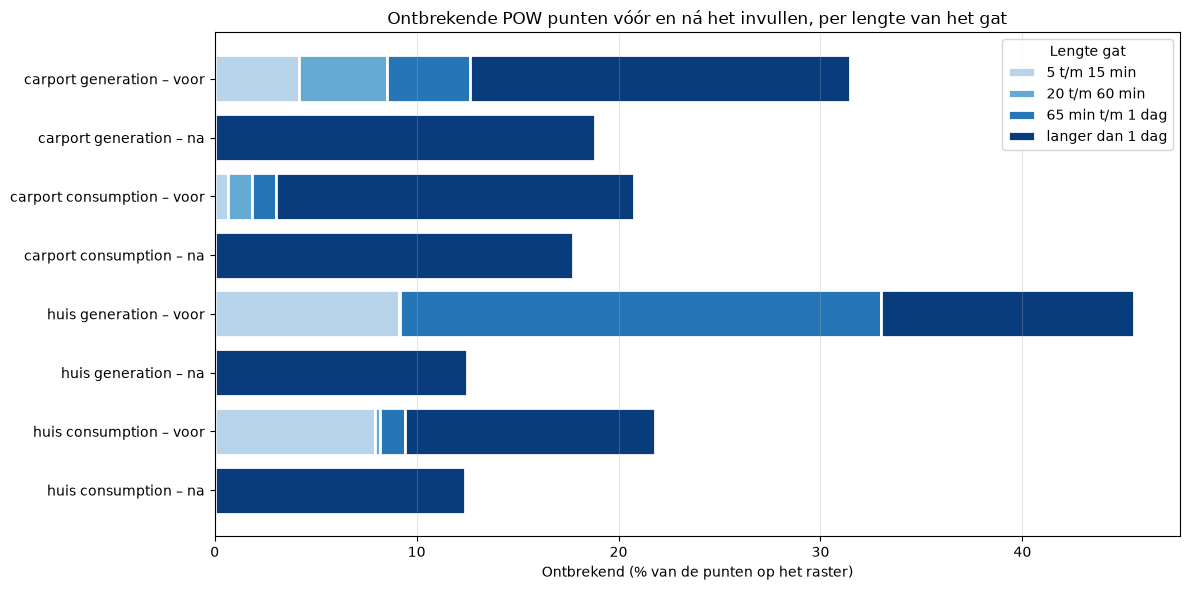

In [ ]:
#Per reeks een balk voor en een balk na, opgedeeld naar lengte van het gat
reeksen = gaten_check[["location", "target_type"]].drop_duplicates().to_numpy()
labels, voor_na = [], []
for locatie, target in reeksen:
    deel = gaten_check[(gaten_check["location"] == locatie) & (gaten_check["target_type"] == target)]
    for moment in ["na", "voor"]:
        labels.append(f"{locatie} {target} – {moment}")
        voor_na.append(deel[moment].to_numpy() / deel["rasterpunten"].iloc[0] * 100)
voor_na = np.array(voor_na)

#Eén kleur, van licht (kort gat) naar donker (lang gat)
kleuren = plt.cm.Blues(np.linspace(0.3, 0.95, len(GAT_CATEGORIEEN)))

plt.figure(figsize=(12, 6))
links = np.zeros(len(labels))
for i, (categorie, kleur) in enumerate(zip(GAT_CATEGORIEEN, kleuren)):
    plt.barh(labels, voor_na[:, i], left=links, color=kleur, edgecolor="white", linewidth=2, label=categorie)
    links += voor_na[:, i]

plt.xlabel("Ontbrekend (% van de punten op het raster)")
plt.title("Ontbrekende POW punten vóór en ná het invullen, per lengte van het gat")
plt.legend(title="Lengte gat")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

> Expres alleen op verbruik en opwekking (consumption en generation, omdat **DEZE** voorspelt moeten worden).

In [ ]:
#Supply en accu (storage) dus niet imputen
huis_supply_raster["pow_imputed"] = huis_supply_raster["pow_w"]
huis_supply_raster["is_imputed"] = False
huis_supply_raster["impute_methode"] = None

carport_supply_raster["pow_imputed"] = carport_supply_raster["pow_w"]
carport_supply_raster["is_imputed"] = False
carport_supply_raster["impute_methode"] = None

carport_accu_raster["pow_imputed"] = carport_accu_raster["pow_w"]
carport_accu_raster["is_imputed"] = False
carport_accu_raster["impute_methode"] = None

5. Impute verandering overzicht
---
Overzicht met totaal aantal punten op het raster, echte pow punten, hoeveel er ontbreken en hoeveel er na impute nog steeds ontbreken

In [ ]:
overzicht = pd.DataFrame([
    ["huis",
     "consumption",
     len(huis_verbruik_raster),
     huis_verbruik_raster["is_observed"].sum(),
     huis_verbruik_raster["pow_w"].isna().sum(),
     huis_verbruik_raster["is_imputed"].sum(),
     huis_verbruik_raster["pow_imputed"].isna().sum()],

     ["huis",
      "generation",
      len(huis_opwekking_raster), 
      huis_opwekking_raster["is_observed"].sum(),
      huis_opwekking_raster["pow_w"].isna().sum(),
      huis_opwekking_raster["is_imputed"].sum(),
      huis_opwekking_raster["pow_imputed"].isna().sum()],

     ["carport",
      "consumption",
      len(carport_verbruik_raster),
      carport_verbruik_raster["is_observed"].sum(),
      carport_verbruik_raster["pow_w"].isna().sum(),
      carport_verbruik_raster["is_imputed"].sum(),
      carport_verbruik_raster["pow_imputed"].isna().sum()],

     ["carport",
      "generation",
      len(carport_opwekking_raster),
      carport_opwekking_raster["is_observed"].sum(),
      carport_opwekking_raster["pow_w"].isna().sum(),
      carport_opwekking_raster["is_imputed"].sum(),
      carport_opwekking_raster["pow_imputed"].isna().sum()]],
      
      columns=["location", "target_type", "rasterpunten", "echte_pow", "origineel_ontbrekend",
              "kort_geimputeerd", "nog_ontbrekend"])

In [ ]:
overzicht["percentage_ontbrekend_gevuld"] = (overzicht["kort_geimputeerd"] / overzicht["origineel_ontbrekend"] * 100)
overzicht

,location,target_type,rasterpunten,echte_pow,origineel_ontbrekend,kort_geimputeerd,nog_ontbrekend,percentage_ontbrekend_gevuld
0,huis,consumption,263808,206302,57506,24819,32687,43.158975
1,huis,generation,263737,143660,120077,87066,33011,72.508474
2,carport,consumption,263018,208384,54634,7937,46697,14.527584
3,carport,generation,263017,180221,82796,33200,49596,40.098555


6. Omzetten naar long format
---

In [ ]:
prep_long = pd.concat(
    [huis_verbruik_raster, huis_opwekking_raster, huis_supply_raster,
     carport_verbruik_raster, carport_opwekking_raster, carport_supply_raster, carport_accu_raster],
     ignore_index=True)

prep_long = (
    prep_long[["timestamp",
               "location",
               "target_type",
               "pow_w",
               "pow_imputed",
               "is_observed",
               "is_conflict",
               "is_imputed",
               "impute_methode"]].sort_values(["location", "target_type", "timestamp"]).reset_index(drop=True))

In [ ]:
prep_long.head()

,timestamp,location,target_type,pow_w,pow_imputed,is_observed,is_conflict,is_imputed,impute_methode
0,2024-03-08 01:00:00+01:00,carport,consumption,786.222222,786.222222,True,False,False,None
1,2024-03-08 01:05:00+01:00,carport,consumption,3108.181818,3108.181818,True,False,False,None
2,2024-03-08 01:10:00+01:00,carport,consumption,3253.111111,3253.111111,True,False,False,None
3,2024-03-08 01:15:00+01:00,carport,consumption,3249.264706,3249.264706,True,False,False,None
4,2024-03-08 01:20:00+01:00,carport,consumption,1446.435897,1446.435897,True,False,False,None


7. Alleen consumption en generation
---
- Deze moeten voorspelt worden

In [ ]:
targets_long = prep_long[prep_long["target_type"].isin(["consumption", "generation"])].copy()

targets_long.groupby(["location", "target_type"]).agg(
    aantal_rijen=("timestamp", "size"),
    echte_pow=("is_observed", "sum"),
    geimputeerd=("is_imputed", "sum"),
    conflicts=("is_conflict", "sum"))

aantal_rijen  echte_pow  geimputeerd  conflicts
location target_type                                                 
carport  consumption        263018     208384         7937          1
         generation         263017     180221        33200          1
huis     consumption        263808     206302        24819          1
         generation         263737     143660        87066          0

8. Opslaan
---

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prep_long.to_parquet(OUTPUT_DIR / "prepared_energy_long.parquet", index=False)
targets_long.to_parquet(OUTPUT_DIR / "forecast_targets_long.parquet", index=False)
overzicht.to_parquet(OUTPUT_DIR / "data_preparation_overzicht.parquet", index=False)

In [ ]:
def ontbrekend_voor_en_na(rasters):
    rijen = []
    for df in rasters:
        totaal = len(df)
        voor = df["pow_w"].isna().sum()
        na = df["pow_imputed"].isna().sum()

        rijen.append({
            "location": df["location"].iloc[0],
            "target_type": df["target_type"].iloc[0],
            "ontbrekend_voor_%": round(voor / totaal * 100, 2),
            "ontbrekend_na_%": round(na / totaal * 100, 2),
            "ingevuld_%": round((voor - na) / voor * 100, 1) if voor else 0.0})

    tabel = pd.DataFrame(rijen)

    #Totaal over alle reeksen samen, op basis van punten (niet het gemiddelde van de percentages)
    totaal = sum(len(df) for df in rasters)
    voor = sum(df["pow_w"].isna().sum() for df in rasters)
    na = sum(df["pow_imputed"].isna().sum() for df in rasters)
    tabel.loc[len(tabel)] = ["totaal", "",
                             round(voor / totaal * 100, 2),
                             round(na / totaal * 100, 2),
                             round((voor - na) / voor * 100, 1) if voor else 0.0]

    return tabel


ontbrekend_voor_en_na([huis_verbruik_raster, huis_opwekking_raster,
                       carport_verbruik_raster, carport_opwekking_raster])

,location,target_type,ontbrekend_voor_%,ontbrekend_na_%,ingevuld_%
0,huis,consumption,21.80,12.39,43.2
1,huis,generation,45.53,12.52,72.5
2,carport,consumption,20.77,17.75,14.5
3,carport,generation,31.48,18.86,40.1
4,totaal,,29.90,15.38,48.6
